#***AI Based Loan Approval System***
A classification project that predicts loan approval outcomes from applicant and loan-application information using the kaggle loan Prediction Problem dataset.

***Objective:*** Build and evaluate ML classifiers as a decision support demonstration, inspect influential features, and predict the likely outcome for an example application.

###Library import

In [ ]:
import os
from pathlib import Path
import warnings
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

##Downloading & locating of dataset:

In [ ]:
dataset_path = kagglehub.dataset_download(
    "altruistdelhite04/loan-prediction-problem-dataset"
)
print("Path to dataset files:", dataset_path)
csv_files = list(Path(dataset_path).rglob("*.csv"))

print("\nCSV files found:")
for file in csv_files:
    print("-", file.relative_to(dataset_path))

if not csv_files:
    raise FileNotFoundError(
        "No CSV files were found in the download dataset. "
        "Check the Kaggle dataset access and download."
    )
train_file = None
df =None

for file in csv_files:
    try:
        candidate = pd.read_csv(file)
        normalized_columns = {str(col).strip().lower() for col in candidate.columns}
        if "loan_status" in normalized_columns:
            train_file = file
            df = candidate
            break
    except Exception as exc:
        print(f"Could not read {file.name}: {exc}")

if df is None:
    raise ValueError(
        "Could not find a CSV containing the Loan_Status target. "
        "Inspect the listed files and select the labeled training CSV."
    )

# Normalize accidental whitespace in column names.
df.columns = df.columns.astype(str).str.strip()

print("\nSelection training file:", train_file.name)
print("Dataset shape:", df.shape)
display(df.head())


Using Colab cache for faster access to the 'loan-prediction-problem-dataset' dataset.
Path to dataset files: /kaggle/input/loan-prediction-problem-dataset

CSV files found:
- test_Y3wMUE5_7gLdaTN.csv
- train_u6lujuX_CVtuZ9i.csv

Selection training file: train_u6lujuX_CVtuZ9i.csv
Dataset shape: (614, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


##Explore the data

In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Value:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Columns:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null   

,missing_count
Credit_History,50
Self_Employed,32
LoanAmount,22
Dependents,15
Loan_Amount_Term,14
Gender,13
Married,3
Education,0
Loan_ID,0
CoapplicantIncome,0



Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


Target distribution:


,count
Loan_Status,
Y,422
N,192


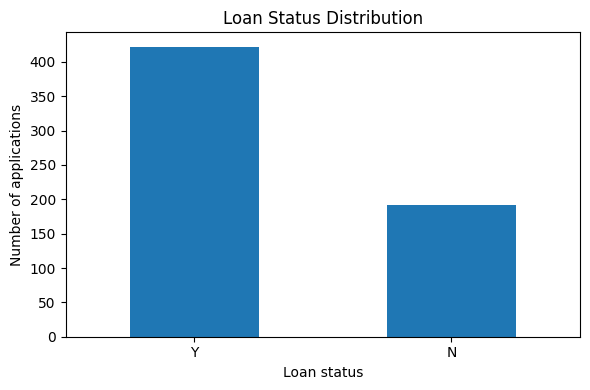

In [ ]:
target_column = next(
    (col for col in df.columns if col.strip().lower() == "loan_status"),
    None
)
if target_column is None:
    raise ValueError("Target column Loan_Status was not found.")

print("Target distribution:")
display(df[target_column].value_counts(dropna=False).to_frame("count"))

ax = df[target_column].value_counts(dropna=False).plot(
    kind="bar", figsize=(6, 4), rot=0, title="Loan Status Distribution"
)
ax.set_xlabel("Loan status")
ax.set_ylabel("Number of applications")
plt.tight_layout()
plt.show()

##Clean & prepare features

In [ ]:
# Clean target labels and remove rows without a known outcome
df = df.copy()
df[target_column] = df [target_column].astype("string").str.strip()
df = df[df[target_column].notna() & (df[target_column] != "")].copy()

unique_target_values = set(df[target_column].dropna().astype(str).str.upper().unique())
if unique_target_values.issubset({"Y", "N"}):
    y = df[target_column].str.upper().map({"N": 0, "Y": 1}).astype(int)
    target_mapping = {"N": 0, "Y": 1}
elif unique_target_values.issubset({"0", "1"}):
    y = df[target_column].astype(int)
    target_mapping = {"0": 0, "1": 1}
else:
    #General fallback for two-class targets.
    values = sorted(df[target_column].astype(str).unique())
    if len(values) != 2:
        raise ValueError(
            f"Expected a binary loan approval target,"
        )
    mapping = {values[0]: 0, values[1]: 1}
    y = df[target_column].astype(str).map(mapping).astype(int)
    target_mapping = mapping

drop_columns = [target_column]
drop_columns += [col for col in df.columns if col.strip().lower() == "loan_id"]
X = df.drop(columns=drop_columns).copy()

# Remove features that are entirely empty.
all_missing_columns = X.columns[X.isna().all()].tolist()
if all_missing_columns:
    print("Dropping entirely missing columns:", all_missing_columns)

# Convert target and features to consistent row indices.
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

print("Target mapping:", target_mapping)
print("Feature matrix shape:", X.shape)
print("Approval rate in available labeled data:", round(float(y.mean()), 3))
display(X.head())

Target mapping: {'N': 0, 'Y': 1}
Feature matrix shape: (614, 11)
Approval rate in available labeled data: 0.687


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban


##Train-test split and preprocessing

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessing, numeric_features),
        ("categorical", categorical_preprocessing, categorical_features)
    ],
    remainder="drop"
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numerical features:", numeric_features)
print("Categorical feature", categorical_features)

Training rows: 491
Testing rows: 123
Numerical features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical feature ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


##Train classification models


**Models in use:**
- Logistic Regression
- Random Forest Classifier

In [ ]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight=None,
            random_state=RANDOM_STATE
        ))
      ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            class_weight=None,
            n_jobs=-1
        ))
    ])
}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Random Forest trained successfully.


##Evaluate model performance

In [ ]:
results = []
for name, pipeline in models.items():
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else None

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (approved)": precision_score(y_test, predictions, zero_division=0),
        "Recall (approved)": recall_score(y_test, predictions, zero_division=0),
        "F1 (approved)": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": (
            roc_auc_score(y_test, probabilities)
            if probabilities is not None and y_test.nunique() == 2
            else np.nan
        )
    }
    results.append(row)

results_df = pd.DataFrame(results).sort_values(
    by="F1 (approved)", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision (approved),Recall (approved),F1 (approved),ROC-AUC
0,Random Forest,0.8537,0.8317,0.9882,0.9032,0.8238
1,Logistic Regression,0.8537,0.8384,0.9765,0.9022,0.8260


In [ ]:
# Select the best baseline by F1 for the positive (approved) class.
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Selected baseline model:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0,
    target_names=["Not approved (0)", "Approved (1)"]
))

Selected baseline model: Random Forest

Classification report:
                  precision    recall  f1-score   support

Not approved (0)       0.95      0.55      0.70        38
    Approved (1)       0.83      0.99      0.90        85

        accuracy                           0.85       123
       macro avg       0.89      0.77      0.80       123
    weighted avg       0.87      0.85      0.84       123



##Confusion matrix

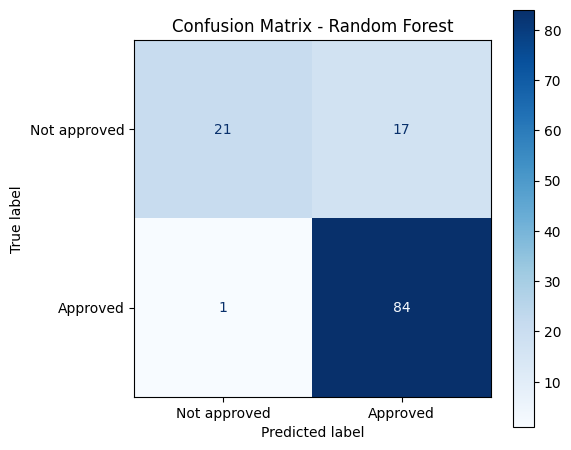

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Not approved", "Approved"],
    cmap="Blues",
    values_format="d",
    ax=ax
)
ax.set_title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

##Analyze feature influence

,Feature,Importance
844,numeric__Credit_History_1.0,0.225318
843,numeric__Credit_History_0.0,0.206901
858,categorical__Property_Area_Semiurban,0.045456
416,numeric__CoapplicantIncome_0.0,0.022373
857,categorical__Property_Area_Rural,0.021332
847,categorical__Married_No,0.017180
854,categorical__Education_Not Graduate,0.015510
841,numeric__Loan_Amount_Term_360.0,0.015182
853,categorical__Education_Graduate,0.014047
681,numeric__LoanAmount_80.0,0.013468


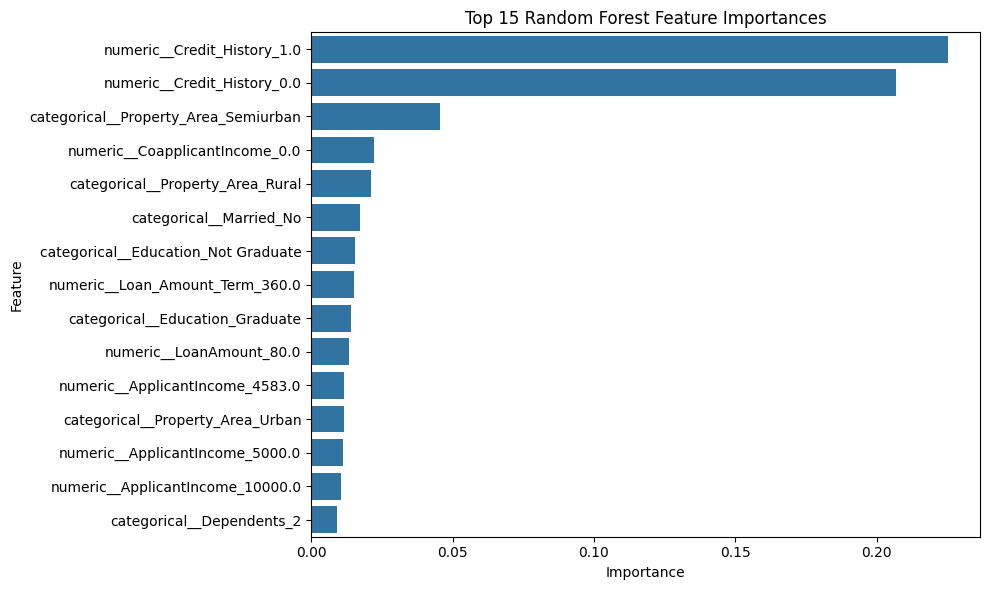

In [ ]:
forest_pipeline = models["Random Forest"]
fitted_preprocessor = forest_pipeline.named_steps["preprocessing"]
forest_classifier = forest_pipeline.named_steps["classifier"]

try:
    transformed_feature_names = fitted_preprocessor.get_feature_names_out()
    importances = forest_classifier.feature_importances_
    importance_df = pd.DataFrame({
        "Feature": transformed_feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False).head(15)

    display(importance_df)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title("Top 15 Random Forest Feature Importances")
    plt.tight_layout()
    plt.show()
except Exception as exc:
    print("Could not produce transformed feature importances:", exc)


##Predict an example application

In [ ]:
# Build a schema-compatible example from the training data's median/mode values.
example_applicant = {}
for col in X.columns:
    if col in numeric_features:
        example_applicant[col] = X_train[col].median()
    else:
        modes = X_train[col].mode(dropna=True)
        example_applicant[col] = modes.iloc[0] if not modes.empty else np.nan

# Illustrative values for common columns in the Kaggle Loan Prediction dataset.
example_overrides = {
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "0",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 5000,
    "CoapplicantIncome": 1500,
    "LoanAmount": 150,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban"
}

for col, value in example_overrides.items():
    if col in X.columns:
        example_applicant[col] = value

example_df = pd.DataFrame([example_applicant]).reindex(columns=X.columns)
display(example_df.T.rename(columns={0: "Example value"}))

predicted_class = int(best_model.predict(example_df)[0])
predicted_probability = float(best_model.predict_proba(example_df)[0, 1])

inverse_mapping = {value: key for key, value in target_mapping.items()}
predicted_label = inverse_mapping.get(predicted_class, predicted_class)

print("Model:", best_model_name)
print("Predicted class:", predicted_label)
print(f"Estimated probability of class 1: {predicted_probability:.1%}")


,Example value
Gender,Male
Married,Yes
Dependents,0
Education,Graduate
Self_Employed,No
ApplicantIncome,5000
CoapplicantIncome,1500
LoanAmount,150
Loan_Amount_Term,360
Credit_History,1.0


Model: Random Forest
Predicted class: Y
Estimated probability of class 1: 72.7%


##Reusable prediction function

In [ ]:
def predict_loan_status(applicant_features, model=best_model):
    """Predict a loan-status class and estimated class-1 probability.

    Parameters
    ----------
    applicant_features : dict
        Applicant and loan features keyed by the original dataset column names.
    model : fitted sklearn Pipeline
        Trained classification pipeline.

    Returns
    -------
    dict
        Predicted class, mapped label, and estimated probability of class 1.
    """
    applicant_row = pd.DataFrame([applicant_features]).reindex(columns=X.columns)
    predicted = int(model.predict(applicant_row)[0])
    probability = float(model.predict_proba(applicant_row)[0, 1])
    label = inverse_mapping.get(predicted, predicted)

    return {
        "predicted_class": predicted,
        "predicted_label": label,
        "probability_class_1": probability
    }

print(predict_loan_status(example_applicant))


{'predicted_class': 1, 'predicted_label': 'Y', 'probability_class_1': 0.7271049195687831}


##Conclusions and possible improvements

This notebook demonstrates an end-to-end classification workflow: data download, exploratory analysis, preprocessing, model training, held-out evaluation, confusion matrix, feature-importance inspection, and a reusable prediction function.

Potential improvements:
- Use cross-validation and a separate validation set for model selection.
- Tune classification thresholds based on documented business costs rather than defaulting automatically to 0.5.
- Evaluate calibration, subgroup performance, false-positive/false-negative rates, and fairness risks.
- Document data provenance, dataset licensing, and limitations before sharing.
- Add input validation and a small interface only after the model has been appropriately assessed.

##Dataset Reference:

- Kaggle dataset: [Loan Prediction Problem Dataset](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset)
- Main libraries: pandas, NumPy, scikit-learn, Matplotlib, Seaborn, kagglehub

**Important:** benchmark metrics from this notebook are dataset- and split-specific. They do not establish that the model is suitable for real lending decisions.
